# 01 · The fake community (simulator)

**Steps T1 and T2 of the project plan.** We can't study BOING's real members, so this notebook invents a realistic community:
2,000 users and 150 groups across 10 topics, who joins what, friendships, posts, likes and blocks. It saves everything as CSV files
in `data/sim_v1/`, with exactly the columns of the plan's "Data format" page.

Each fake user also gets **hidden interests** (for example 70% languages, 30% fitness) and each group a **hidden topic**.
A recommender must never read them: we use them only like an answer key, to check whether its suggestions make sense.

**How to run it.** Locally: open it in VS Code or Jupyter and choose *Run All*. In Google Colab: *File → Upload notebook*, then
*Runtime → Run all*; the last cell downloads the files as a zip. Same seed, same community, every time.

| Section | What it does |
|---|---|
| 0 | Settings (T1: check that Python and the libraries work) |
| 1 | The 10 topics, with name and text patterns |
| 2 | 150 groups |
| 3 | 2,000 users and their hidden interests |
| 4 | Who joins what |
| 5 | Friendships, posts, likes, blocks, opt-in topics, "not interested" |
| 6 | Save the files |
| 7 | Checks |
| 8 | Summary and the group-size chart |

## 0 · Settings

T1 is done when this cell runs with no red error. Every number that shapes the community is here, so it can be changed in one place.

In [1]:
import sys, zipfile
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn

SEED = 0
rng = np.random.default_rng(SEED)   # one random generator: same seed, same community on every run

N_USERS = 2000
N_GROUPS = 150
TODAY = 365               # days since launch; every day in the files is between 0 and TODAY
NEW_DAYS = 30             # "new" = signed up (or created) in the last 30 days
SMALL = 10                # a "small" group has fewer than 10 members (rule R4)
SHARE_NEW_USERS = 0.15    # about 15% of users are new, with only 0-2 groups
SHARE_RECENT_GROUPS = 0.20  # about 20% of groups were created in the last 30 days
EXPLORE = 0.12            # chance that a join is "a random one", outside the user's favourite topics

# Find the project folder whether we run from notebooks/ (locally) or from /content (Colab)
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
OUT = ROOT / 'data' / 'sim_v1'
FIGS = ROOT / 'figures'
OUT.mkdir(parents=True, exist_ok=True)
FIGS.mkdir(parents=True, exist_ok=True)

print('Python', sys.version.split()[0], '| numpy', np.__version__, '| pandas', pd.__version__,
      '| scikit-learn', sklearn.__version__, '| matplotlib', matplotlib.__version__)
print('Files will be saved in data/sim_v1')

Python 3.12.10 | numpy 2.5.4 | pandas 3.0.6 | scikit-learn 1.9.1 | matplotlib 3.11.2
Files will be saved in data/sim_v1


## 1 · The topics

Ten topics. `share` is how popular each topic is among users (coding and languages are common, physics is rarer).
For each topic: a few **subjects**, 5 **name patterns** and 5 **description patterns** that get mixed, and a few **post lines**.
`{s}` is replaced by the subject (in lower case inside sentences, unless it's a name like Spanish or SAT). All texts are made up and contain no personal information.

In [2]:
TOPICS = {
    'languages': dict(share=.14,
        subjects=['Spanish', 'French', 'Japanese', 'Korean', 'Arabic', 'German', 'Italian', 'Mandarin', 'Portuguese', 'English'],
        names=['{s} in 90 days', '{s} evening chat', '{s} for beginners', '{s} conversation club', 'Daily {s}'],
        abouts=['Daily practice for beginners. Ten minutes a day, no pressure.',
                'Speak {s} with people at your level. Weekly voice chats.',
                'Grammar questions, a word of the day and lots of mistakes, on purpose.',
                'Getting ready for a trip or an exam in {s}? Practise here.',
                'Learners and native speakers helping each other with {s}.'],
        posts=['Day {n} of {s}: I ordered a coffee without switching languages!',
               'Anyone up for a {s} chat this weekend?',
               'Finally understood a whole podcast episode in {s}.',
               'Word of the day in {s}, guess the meaning before you look it up.']),
    'coding': dict(share=.16,
        subjects=['Python', 'JavaScript', 'Web dev', 'Game dev', 'Data science', 'C++', 'Rust', 'Algorithms', 'SQL', 'App building'],
        names=['Daily {s}', '{s} study group', '{s} from zero', '{s} project club', 'Learn {s} together'],
        abouts=['One small exercise a day and a project every week.',
                'Stuck on a bug? Ask here, no question is too basic.',
                'Build something real with {s} by the end of the month.',
                'Code reviews, tips and resources for {s}.',
                'Pair up and keep each other on track.'],
        posts=['Day {n} of {s}: my first program that actually works.',
               'Spent two hours on a bug. It was a missing bracket.',
               'Sharing my {s} project from this week, feedback welcome.',
               'What is the best free resource for {s}?']),
    'maths': dict(share=.09,
        subjects=['Calculus', 'Linear algebra', 'Statistics', 'Probability', 'Discrete maths', 'Geometry', 'Algebra', 'Number theory'],
        names=['{s} help desk', '{s} problem of the day', '{s} study group', 'Mastering {s}', '{s} without tears'],
        abouts=['Post a problem, get hints, not answers.',
                'A new {s} problem every morning.',
                'Weekly sessions before the exam.',
                'Explain it simply: {s} edition.',
                'From the basics to the hard parts, one step at a time.'],
        posts=['Problem {n}: can someone check my {s} solution?',
               'This {s} trick finally made sense to me today.',
               'Study session tonight, who is in?',
               'Week {n} of {s}, slowly getting there.']),
    'physics': dict(share=.05,
        subjects=['Mechanics', 'Electromagnetism', 'Quantum physics', 'Thermodynamics', 'Astronomy', 'Relativity', 'Optics'],
        names=['{s} study group', '{s} explained', '{s} problem sets', 'Curious about {s}', '{s} club'],
        abouts=['Problem sets and explanations, every week.',
                'Ask anything about {s}, beginners welcome.',
                'We read one chapter a week and discuss it.',
                'Experiments, videos and questions about {s}.',
                'Getting ready for the {s} exam together.'],
        posts=['Problem set {n} done. Question 4 was brutal.',
               'Great video on {s}, sharing it here.',
               'Can someone explain this {s} idea in simple words?',
               'Week {n}: finished the {s} chapter.']),
    'fitness': dict(share=.12,
        subjects=['Running', 'Calisthenics', 'Yoga', 'Weightlifting', 'Cycling', 'Swimming', 'Stretching', 'Hiking'],
        names=['{s} every day', '{s} crew', '{s} for beginners', '30 days of {s}', 'Morning {s}'],
        abouts=['Log your sessions and cheer each other on.',
                'Beginner friendly, all levels welcome.',
                'A 30-day plan, one small step each day.',
                'Tips, routines, and rest days too.',
                'A weekly {s} challenge, no pressure.'],
        posts=['Day {n} of {s} done, feeling good.',
               'New personal best in {s} today!',
               'Rest day today. Back at it tomorrow.',
               'Who is joining the {s} challenge this week?']),
    'art': dict(share=.08,
        subjects=['Drawing', 'Pixel art', 'Watercolour', 'Digital painting', 'Sketching', 'Character design', 'Photography', '3D modelling'],
        names=['Daily {s}', '{s} club', '{s} sketchbook', '{s} for fun', '{s} challenge'],
        abouts=['Share one piece a day, however small.',
                'Feedback, tips and weekly themes.',
                'For beginners who want to start {s}.',
                'A new {s} prompt every Monday.',
                'No judgement, just making things.'],
        posts=['Day {n} of {s}, here is today\'s piece.',
               'Tried a new {s} technique, what do you think?',
               'This week\'s theme is "frogs".',
               'Any tips for getting better at {s}?']),
    'music': dict(share=.09,
        subjects=['Guitar', 'Piano', 'Music production', 'Singing', 'Drums', 'Music theory', 'Beatmaking', 'Violin'],
        names=['{s} practice room', '{s} for beginners', 'Daily {s}', '{s} club', 'Learn {s} together'],
        abouts=['Practise every day and share your progress.',
                'Beginner friendly, questions welcome.',
                'Weekly challenges and feedback on {s}.',
                'Tips, songs and exercises for {s}.',
                'Find people to practise {s} with.'],
        posts=['Day {n} of {s}: finally got that part right.',
               'Recorded my first {s} piece, be kind!',
               'How long do you practise {s} every day?',
               'Week {n} of {s}, my fingers hurt but it\'s worth it.']),
    'exam_prep': dict(share=.13,
        subjects=['Finals', 'SAT', 'MCAT', 'GRE', 'IELTS', 'AP exams', 'Midterms', 'Entrance exams'],
        names=['{s} study hall', '{s} countdown', '{s} prep squad', '{s} accountability group', 'Beat the {s}'],
        abouts=['Silent study sessions every evening.',
                'Daily check-ins until exam day.',
                'Practice questions and study plans for {s}.',
                'We keep each other on track until the {s}.',
                'Tips, schedules and moral support.'],
        posts=['{n} days left until {s}. Study session tonight?',
               'Finished a full practice test for {s}.',
               'How do you stay focused during {s} season?',
               'Made a study plan for {s}, sharing it here.']),
    'careers': dict(share=.07,
        subjects=['Internships', 'Resumes', 'Job interviews', 'Freelancing', 'Startups', 'Networking', 'Public speaking', 'Portfolios'],
        names=['{s} help', '{s} club', '{s} 101', 'Getting good at {s}', '{s} circle'],
        abouts=['Share tips and review each other\'s work.',
                'Practice sessions and honest feedback.',
                'Everything about {s}, for students.',
                'Weekly meetups about {s}.',
                'From first steps to first offers.'],
        posts=['Week {n}: sent three applications.',
               'Any advice on {s}? I start next week.',
               'Practised {s} today, it went better than I expected.',
               'Sharing a guide about {s} that helped me.']),
    'habits': dict(share=.07,
        subjects=['Sleep', 'Journaling', 'Reading', 'Meditation', 'Early mornings', 'Less screen time', 'Focus sessions', 'Drinking water'],
        names=['{s} streak', 'Better {s}', '{s} club', '30 days of {s}', '{s} together'],
        abouts=['Small daily steps, checked in together.',
                'Share your streak and keep going.',
                'A 30-day challenge, starting every Monday.',
                'Tips and support for building the habit.',
                'No pressure, just progress.'],
        posts=['Day {n} of {s}, still going.',
               'Missed a day, starting again today.',
               'What helps you stick with {s}?',
               'Week {n} of {s}: I feel the difference.']),
}
KEEP_CAPITALS = {'Python', 'JavaScript', 'Rust', 'SQL', 'C++', 'SAT', 'MCAT', 'GRE', 'IELTS', 'AP', '3D'} | set(TOPICS['languages']['subjects'])

def in_sentence(s):
    # "Guitar" -> "guitar" inside a sentence, but "Spanish", "Python" and "SAT" keep their capitals
    return s if s.split()[0] in KEEP_CAPITALS else s[0].lower() + s[1:]

TOPIC_NAMES = list(TOPICS)
T = len(TOPIC_NAMES)
POP = np.array([TOPICS[t]['share'] for t in TOPIC_NAMES])
POP = POP / POP.sum()
print(T, 'topics:', ', '.join(f'{t} {p:.0%}' for t, p in zip(TOPIC_NAMES, POP)))

10 topics: languages 14%, coding 16%, maths 9%, physics 5%, fitness 12%, art 8%, music 9%, exam_prep 13%, careers 7%, habits 7%


## 2 · The groups

150 groups. Popular topics get more groups (at least 6 each). Each group gets a unique name and a description mixed from its topic's patterns.

- **When it was created:** the first group of each topic exists from launch (day 0). 20% of groups are recent (last 30 days); the rest were created
  at some point during the year. Ids follow creation order, like in a real database.
- **Open:** 85% of groups let anyone join (`open = 1`); the others need approval.
- **Hidden by moderators:** 3 groups (2%), so the safety rules can be tested.

In [3]:
# How many groups per topic: proportional to popularity, at least 6 each, exactly N_GROUPS in total
per_topic = np.maximum(6, np.round(POP * N_GROUPS)).astype(int)
while per_topic.sum() != N_GROUPS:
    per_topic[per_topic.argmax()] += 1 if per_topic.sum() < N_GROUPS else -1

rows, used = [], set()
for t, n in zip(TOPIC_NAMES, per_topic):
    spec = TOPICS[t]
    # every (subject, name pattern) pair, shuffled; keep the first n unique names
    combos = [(s, p) for s in spec['subjects'] for p in spec['names']]
    for i in rng.permutation(len(combos)):
        s, p = combos[i]
        name = p.format(s=s)
        if name in used:
            continue
        used.add(name)
        about = spec['abouts'][rng.integers(len(spec['abouts']))].format(s=in_sentence(s))
        rows.append(dict(name=name, about=about, topic=t, subject=s))
        if sum(r['topic'] == t for r in rows) == n:
            break
groups = pd.DataFrame(rows)

# Creation day: one launch group per topic on day 0, 20% recent, the rest spread over the year
launch = groups.groupby('topic').head(1).index
others = groups.index.difference(launch)
recent = rng.choice(others, size=round(SHARE_RECENT_GROUPS * N_GROUPS), replace=False)
groups['created_day'] = rng.integers(1, TODAY - NEW_DAYS + 1, size=len(groups))
groups.loc[launch, 'created_day'] = 0
groups.loc[recent, 'created_day'] = rng.integers(TODAY - NEW_DAYS + 1, TODAY + 1, size=len(recent))
groups['open'] = (rng.random(len(groups)) < 0.85).astype(int)
groups['hidden_by_mods'] = 0
groups.loc[rng.choice(others, size=3, replace=False), 'hidden_by_mods'] = 1

# Ids follow creation order (ids start at 1: group_id 0 means "not in a group" in posts.csv)
groups = groups.sort_values(['created_day', 'name'], kind='stable').reset_index(drop=True)
groups.insert(0, 'group_id', np.arange(1, len(groups) + 1))
G = len(groups)
g_topic = groups['topic'].map(TOPIC_NAMES.index).to_numpy()   # topic index of each group (row order)
g_created = groups['created_day'].to_numpy()
g_open = groups['open'].to_numpy()
groups.head(8)

,group_id,name,about,topic,subject,created_day,open,hidden_by_mods
0,1,3D modelling club,A new 3D modelling prompt every Monday.,art,3D modelling,0,1,0
1,2,Astronomy club,"Problem sets and explanations, every week.",physics,Astronomy,0,1,0
2,3,Daily Rust,Build something real with Rust by the end of t...,coding,Rust,0,0,0
3,4,Finals countdown,We keep each other on track until the finals.,exam_prep,Finals,0,1,0
4,5,Guitar club,"Tips, songs and exercises for guitar.",music,Guitar,0,1,0
5,6,Journaling streak,Share your streak and keep going.,habits,Journaling,0,1,0
6,7,Korean conversation club,Getting ready for a trip or an exam in Korean?...,languages,Korean,0,1,0
7,8,Mastering Probability,"From the basics to the hard parts, one step at...",maths,Probability,0,1,0


## 3 · The users and their hidden interests

2,000 users. 15% are **new** (signed up in the last 30 days); the others signed up during the year.
Each user likes 1 to 3 topics (40% one, 40% two, 20% three), picked according to topic popularity, with random weights that add up to 1:
these are the **hidden interests**. Each user is also given how many groups they will join: 2 to 8 (fewer is more common), or 0 to 2 for new users.

In [4]:
n_new = round(SHARE_NEW_USERS * N_USERS)
is_new = np.zeros(N_USERS, dtype=bool)
is_new[rng.choice(N_USERS, size=n_new, replace=False)] = True
u_created = np.where(is_new,
                     rng.integers(TODAY - NEW_DAYS + 1, TODAY + 1, size=N_USERS),
                     rng.integers(0, TODAY - NEW_DAYS + 1, size=N_USERS))

# Hidden interests: a users x topics matrix of weights (0 = not a favourite topic)
W = np.zeros((N_USERS, T))
for u in range(N_USERS):
    k = rng.choice([1, 2, 3], p=[.4, .4, .2])
    favs = rng.choice(T, size=k, replace=False, p=POP)
    W[u, favs] = np.round(rng.dirichlet(np.full(k, 2.0)), 2)
    W[u, favs[0]] += 1 - W[u].sum()          # fix rounding so the weights add up to exactly 1

# How many groups each user will join
n_join = np.where(is_new,
                  rng.choice([0, 1, 2], size=N_USERS, p=[.35, .40, .25]),
                  rng.choice(np.arange(2, 9), size=N_USERS, p=[.20, .20, .17, .14, .12, .10, .07]))

# Ids follow sign-up order
order = np.argsort(u_created, kind='stable')
u_created, is_new, W, n_join = u_created[order], is_new[order], W[order], n_join[order]
user_ids = np.arange(1, N_USERS + 1)

def interests_text(w):
    # e.g. "languages:0.70|fitness:0.30", biggest weight first
    idx = np.argsort(-w)
    return '|'.join(f'{TOPIC_NAMES[i]}:{w[i]:.2f}' for i in idx if w[i] > 0)

print(f'{is_new.sum()} new users ({is_new.mean():.0%}); example interests: {interests_text(W[0])} / {interests_text(W[1])}')

300 new users (15%); example interests: exam_prep:1.00 / art:0.76|maths:0.24


## 4 · Who joins what

First, **every group starts with its creator** as its first member: someone who had already signed up, usually a person who likes the group's topic.

Then every other join is an event on a given day, and we replay all of them in time order, like the platform's history:

- a user's first join happens within 3 days of signing up; the others are spread between sign-up and today;
- only groups that already exist that day can be joined;
- with probability 12% the user picks **a random group**, otherwise a group in **their favourite topics**;
- either way, bigger groups are more likely to be picked: **chance ∝ topic match × (members + 1)**. Groups that need approval count half.

Because big groups attract more members, a few groups grow huge while most stay small: the "rich get richer" effect that real networks show,
and the popularity bias the project fixes.

In [5]:
# Join days for every user, then all events sorted by day
events = []
for u in range(N_USERS):
    k = n_join[u]
    if k == 0:
        continue
    first = min(TODAY, u_created[u] + rng.integers(0, 4))
    rest = rng.integers(u_created[u], TODAY + 1, size=k - 1)
    events += [(d, u) for d in [first, *rest]]
events.sort(key=lambda e: (e[0], rng.random()))

members = np.zeros(G)                          # current member count of each group
joined = [set() for _ in range(N_USERS)]       # groups each user is in
mem_rows = []

# The creator of each group: an established user who signed up before the group was created,
# picked mostly among people who like its topic
for g in range(G):
    can = np.flatnonzero((u_created <= g_created[g]) & ~is_new)
    if len(can) == 0:
        can = np.array([np.argmin(u_created)])   # nobody yet: the very first user
    w = W[can, g_topic[g]] + 0.02
    u = rng.choice(can, p=w / w.sum())
    joined[u].add(g)
    members[g] += 1
    mem_rows.append((user_ids[u], groups.group_id[g], max(g_created[g], u_created[u])))

for day, u in events:
    ok = (g_created <= day)
    ok[list(joined[u])] = False                # can't join the same group twice
    if not ok.any():
        continue
    size_pull = (members + 1) * np.where(g_open == 1, 1.0, 0.5)
    match = W[u, g_topic]                      # the user's weight for each group's topic (0 if not a favourite)
    if rng.random() < EXPLORE or not (ok & (match > 0)).any():
        p = ok * size_pull                     # a random group (bigger ones still more likely)
    else:
        p = ok * match * size_pull             # a group in a favourite topic
    g = rng.choice(G, p=p / p.sum())
    joined[u].add(g)
    members[g] += 1
    mem_rows.append((user_ids[u], groups.group_id[g], day))

memberships = pd.DataFrame(mem_rows, columns=['user_id', 'group_id', 'joined_day'])
in_fav = np.mean([W[uid - 1, g_topic[gid - 1]] > 0 for uid, gid, _ in mem_rows])
print(f'{len(memberships)} memberships; {in_fav:.0%} of them are in one of the user\'s favourite topics')

7959 memberships; 89% of them are in one of the user's favourite topics


## 5 · Friends, posts, likes, blocks and the two new opt-in files

- **Friendships:** each user makes a few friends (about 3 on average, 1 for new users). 80% of the time the friend is someone from one of their groups,
  otherwise anyone. Each pair is saved once, with the smaller id first.
- **Posts:** a few per group (more in bigger groups, at most 25), written by members after they joined. Plus 300 posts outside any group (`group_id = 0`).
  1.5% of posts are hidden by moderators.
- **Likes:** group members like a group post with probability 6%; friends like a profile post with probability 30%.
- **Blocks:** 30 users block someone, usually a person from one of their groups. Blocked pairs are never friends.
- **topics.csv (new, rule R1/R11):** about a third of users chose to share 1-2 topics they like, mostly their real favourites.
- **not_interested.csv (new, rule R7):** a few users pressed "not interested" on a group outside their topics. This button doesn't exist in BOING yet;
  these rows exist only so the rule can be tested.

Then each user gets a **level** (1-100, grows with time on the platform and activity), a **privacy** setting (20% private) and a **suspended** flag (1%).
`is_fake` is 0 for everyone: fake (Sybil) accounts are added later, in experiment E4.

In [6]:
members_of = {g: [] for g in range(G)}                # group row -> [(user row, joined_day)]
groups_of = {u: [] for u in range(N_USERS)}           # user row -> [(group row, joined_day)]
for uid, gid, d in mem_rows:
    members_of[gid - 1].append((uid - 1, d))
    groups_of[uid - 1].append((gid - 1, d))

# Friendships
friends = {}
for u in range(N_USERS):
    for _ in range(rng.poisson(1.0 if is_new[u] else 3.0)):
        if groups_of[u] and rng.random() < 0.8:
            g, du = groups_of[u][rng.integers(len(groups_of[u]))]
            others = [(v, dv) for v, dv in members_of[g] if v != u]
            if not others:
                continue
            v, dv = others[rng.integers(len(others))]
            since = max(du, dv) + rng.integers(0, 15)
        else:
            v = rng.integers(N_USERS)
            if v == u:
                continue
            since = max(u_created[u], u_created[v]) + rng.integers(0, 30)
        a, b = sorted((u, v))
        friends.setdefault((a, b), min(int(since), TODAY))

# Posts and likes
post_rows, like_rows = [], []
def post_text(t, s):
    lines = TOPICS[t]['posts']
    return lines[rng.integers(len(lines))].format(s=in_sentence(s), n=int(rng.integers(2, 60)))

for g in range(G):
    mem = members_of[g]
    if not mem:
        continue
    for _ in range(min(25, rng.poisson(1 + 0.08 * len(mem)))):
        u, du = mem[rng.integers(len(mem))]
        likers = [v for v, _ in mem if v != u and rng.random() < 0.06]
        post_rows.append([u, groups.group_id[g], int(rng.integers(du, TODAY + 1)),
                          post_text(groups.topic[g], groups.subject[g]), likers])

friends_of = {u: [] for u in range(N_USERS)}
for a, b in friends:
    friends_of[a].append(b)
    friends_of[b].append(a)
posters = rng.choice(np.flatnonzero(~is_new), size=300)
for u in posters:
    t = TOPIC_NAMES[W[u].argmax()]
    s = TOPICS[t]['subjects'][rng.integers(len(TOPICS[t]['subjects']))]
    likers = [v for v in friends_of[u] if rng.random() < 0.3]
    post_rows.append([u, 0, int(rng.integers(u_created[u], TODAY + 1)), post_text(t, s), likers])

post_rows.sort(key=lambda r: r[2])                    # post ids follow time order
posts = pd.DataFrame([dict(post_id=i + 1, user_id=user_ids[u], group_id=g, day=d, text=txt, likes=len(lk),
                           hidden_by_mods=int(rng.random() < 0.015))
                      for i, (u, g, d, txt, lk) in enumerate(post_rows)])
likes = pd.DataFrame([(i + 1, user_ids[v]) for i, r in enumerate(post_rows) for v in r[4]],
                     columns=['post_id', 'user_id'])

# Blocks: mostly someone from one of the blocker's groups; blocked pairs stop being friends
block_set = set()
for u in rng.choice(np.flatnonzero(~is_new), size=30, replace=False):
    for _ in range(1 if rng.random() < 0.8 else 2):
        if groups_of[u] and rng.random() < 0.7:
            g, _ = groups_of[u][rng.integers(len(groups_of[u]))]
            v = members_of[g][rng.integers(len(members_of[g]))][0]
        else:
            v = rng.integers(N_USERS)
        if v != u:
            block_set.add((u, v))
            friends.pop(tuple(sorted((u, v))), None)
blocks = pd.DataFrame(sorted((user_ids[u], user_ids[v]) for u, v in block_set), columns=['user_id', 'blocked_id'])
friendships = pd.DataFrame(sorted((user_ids[a], user_ids[b], d) for (a, b), d in friends.items()),
                           columns=['user_a', 'user_b', 'since_day'])

# topics.csv: about a third of users share 1-2 topics, mostly their real favourites
topic_rows = []
for u in range(N_USERS):
    if rng.random() < (0.20 if is_new[u] else 0.35):
        favs = [i for i in np.argsort(-W[u]) if W[u, i] > 0][:rng.integers(1, 3)]
        if rng.random() < 0.10:
            favs.append(rng.integers(T))              # sometimes a topic they're only curious about
        topic_rows += [(user_ids[u], TOPIC_NAMES[i]) for i in dict.fromkeys(favs)]
topics = pd.DataFrame(topic_rows, columns=['user_id', 'topic'])

# not_interested.csv: a few users dismissed a group outside their topics
ni_rows = []
for u in rng.choice(N_USERS, size=60, replace=False):
    outside = [g for g in range(G) if W[u, g_topic[g]] == 0 and g not in joined[u]]
    for g in rng.choice(outside, size=rng.integers(1, 3), replace=False):
        ni_rows.append((user_ids[u], groups.group_id[g], int(rng.integers(max(u_created[u], g_created[g]), TODAY + 1))))
not_interested = pd.DataFrame(sorted(ni_rows), columns=['user_id', 'group_id', 'day'])

# Level, privacy, suspended
n_posts = np.bincount(posts.user_id - 1, minlength=N_USERS)
activity = rng.lognormal(0, 0.35, N_USERS) * (0.6 + 0.1 * n_join + 0.05 * n_posts)
level = np.clip(1 + np.floor(0.9 * activity * (TODAY - u_created) ** 0.6), 1, 100).astype(int)
users = pd.DataFrame(dict(
    user_id=user_ids,
    created_day=u_created,
    level=level,
    privacy=np.where(rng.random(N_USERS) < 0.20, 'private', 'public'),
    suspended=((rng.random(N_USERS) < 0.012) & ~is_new).astype(int),
    interests=[interests_text(w) for w in W],         # hidden
    is_fake=0,                                        # hidden; Sybil accounts come later (E4)
))
print(f'{len(friendships)} friendships, {len(posts)} posts, {len(likes)} likes, {len(blocks)} blocks, '
      f'{topics.user_id.nunique()} users shared topics, {len(not_interested)} "not interested" rows')

5374 friendships, 1080 posts, 7273 likes, 33 blocks, 676 users shared topics, 90 "not interested" rows


## 6 · Save the files

Exactly the columns of the "Data format" page, in that order. Columns marked *hidden* there (`users.interests`, `users.is_fake`, `groups.topic`)
are the answer key: drop them before any data reaches a recommender (the `HIDDEN` list below says which).

In [7]:
COLUMNS = {
    'users.csv':          ['user_id', 'created_day', 'level', 'privacy', 'suspended', 'interests', 'is_fake'],
    'groups.csv':         ['group_id', 'name', 'about', 'open', 'created_day', 'hidden_by_mods', 'topic'],
    'memberships.csv':    ['user_id', 'group_id', 'joined_day'],
    'friendships.csv':    ['user_a', 'user_b', 'since_day'],
    'posts.csv':          ['post_id', 'user_id', 'group_id', 'day', 'text', 'likes', 'hidden_by_mods'],
    'likes.csv':          ['post_id', 'user_id'],
    'blocks.csv':         ['user_id', 'blocked_id'],
    'topics.csv':         ['user_id', 'topic'],
    'not_interested.csv': ['user_id', 'group_id', 'day'],
}
HIDDEN = {'users.csv': ['interests', 'is_fake'], 'groups.csv': ['topic']}   # never shown to a recommender

tables = {'users.csv': users, 'groups.csv': groups, 'memberships.csv': memberships, 'friendships.csv': friendships,
          'posts.csv': posts, 'likes.csv': likes, 'blocks.csv': blocks, 'topics.csv': topics,
          'not_interested.csv': not_interested}
for fname, df in tables.items():
    df[COLUMNS[fname]].sort_values(COLUMNS[fname][:2]).to_csv(OUT / fname, index=False)
    print(f'{fname:20} {len(df):6} rows')

users.csv              2000 rows
groups.csv              150 rows
memberships.csv        7959 rows
friendships.csv        5374 rows
posts.csv              1080 rows
likes.csv              7273 rows
blocks.csv               33 rows
topics.csv              934 rows
not_interested.csv       90 rows


## 7 · Checks

The files are read back from disk and checked. If something is wrong, a cell stops with a red error saying what.

In [8]:
D = {f: pd.read_csv(OUT / f) for f in COLUMNS}
u, g, m, fr, p, lk, b = (D[f] for f in ['users.csv', 'groups.csv', 'memberships.csv', 'friendships.csv',
                                         'posts.csv', 'likes.csv', 'blocks.csv'])
checks = {
    'every file has exactly the agreed columns': all(list(D[f].columns) == c for f, c in COLUMNS.items()),
    'ids are unique': u.user_id.is_unique and g.group_id.is_unique and p.post_id.is_unique,
    'every membership points to a real user and group': m.user_id.isin(u.user_id).all() and m.group_id.isin(g.group_id).all(),
    'nobody is in the same group twice': not m.duplicated(['user_id', 'group_id']).any(),
    'nobody joins before signing up or before the group exists':
        (m.joined_day >= m.user_id.map(u.set_index('user_id').created_day)).all()
        and (m.joined_day >= m.group_id.map(g.set_index('group_id').created_day)).all(),
    'every day is between 0 and TODAY': all(D[f][c].between(0, TODAY).all() for f, c in
        [('users.csv', 'created_day'), ('groups.csv', 'created_day'), ('memberships.csv', 'joined_day'),
         ('friendships.csv', 'since_day'), ('posts.csv', 'day'), ('not_interested.csv', 'day')]),
    'each friendship once, smaller id first': (fr.user_a < fr.user_b).all() and not fr.duplicated(['user_a', 'user_b']).any(),
    'blocked pairs are never friends': not set(map(tuple, np.sort(b[['user_id', 'blocked_id']].to_numpy(), axis=1))) & set(zip(fr.user_a, fr.user_b)),
    'like counts match likes.csv': (p.set_index('post_id').likes == lk.groupby('post_id').size().reindex(p.post_id, fill_value=0)).all(),
    'group posts are written by members': p[p.group_id > 0].merge(m, on=['user_id', 'group_id']).shape[0] == (p.group_id > 0).sum(),
    'levels are between 1 and 100': u.level.between(1, 100).all(),
    'about 15% of users are new, with at most 2 groups': abs((u.created_day > TODAY - NEW_DAYS).mean() - 0.15) < 0.02
        and m[m.user_id.isin(u.user_id[u.created_day > TODAY - NEW_DAYS])].groupby('user_id').size().max() <= 2,
    'no wallet addresses, messages or planner data in any file': not any(
        any(w in c for w in ['wallet', 'message', 'planner', 'coach', 'balance']) for c in sum(COLUMNS.values(), [])),
}
for name, ok in checks.items():
    print('✓' if ok else '✗', name)
assert all(checks.values()), 'Some checks failed (see ✗ above)'

✓ every file has exactly the agreed columns
✓ ids are unique
✓ every membership points to a real user and group
✓ nobody is in the same group twice
✓ nobody joins before signing up or before the group exists
✓ every day is between 0 and TODAY
✓ each friendship once, smaller id first
✓ blocked pairs are never friends
✓ like counts match likes.csv
✓ group posts are written by members
✓ levels are between 1 and 100
✓ about 15% of users are new, with at most 2 groups
✓ no wallet addresses, messages or planner data in any file


## 8 · Summary and the group-size chart

T2 is done when the files open in pandas and the group sizes show **a few huge groups and a long tail of small ones**.

In [9]:
sizes = m.groupby('group_id').size().reindex(g.group_id, fill_value=0)
new_u = u.created_day > TODAY - NEW_DAYS
summary = pd.Series({
    'users': len(u),
    'new users (last 30 days)': f'{new_u.sum()} ({new_u.mean():.0%})',
    'groups': len(g),
    'recent groups (last 30 days)': f'{(g.created_day > TODAY - NEW_DAYS).sum()} ({(g.created_day > TODAY - NEW_DAYS).mean():.0%})',
    f'small groups (< {SMALL} members)': f'{(sizes < SMALL).sum()} ({(sizes < SMALL).mean():.0%})',
    'memberships': len(m),
    'groups per user (established / new)': f'{m.groupby("user_id").size().reindex(u.user_id[~new_u], fill_value=0).mean():.1f} / '
                                            f'{m.groupby("user_id").size().reindex(u.user_id[new_u], fill_value=0).mean():.1f}',
    'largest group': f'{sizes.max()} members',
    'median group': f'{sizes.median():.0f} members',
    'share of memberships in the 10 largest groups': f'{sizes.nlargest(10).sum() / sizes.sum():.0%}',
    'friendships': len(fr), 'posts': len(p), 'likes': len(lk), 'blocks': len(b),
    'private profiles': f'{(u.privacy == "private").mean():.0%}', 'suspended': int(u.suspended.sum()),
})
print(summary.to_string())
print('\nLargest groups:')
print(g.assign(members=sizes.values).nlargest(5, 'members')[['group_id', 'name', 'topic', 'created_day', 'members']].to_string(index=False))

users                                                   2000
new users (last 30 days)                           300 (15%)
groups                                                   150
recent groups (last 30 days)                        30 (20%)
small groups (< 10 members)                         64 (43%)
memberships                                             7959
groups per user (established / new)                4.5 / 0.9
largest group                                    354 members
median group                                      16 members
share of memberships in the 10 largest groups            35%
friendships                                             5374
posts                                                   1080
likes                                                   7273
blocks                                                    33
private profiles                                         22%
suspended                                                 17

Largest groups:
 group_

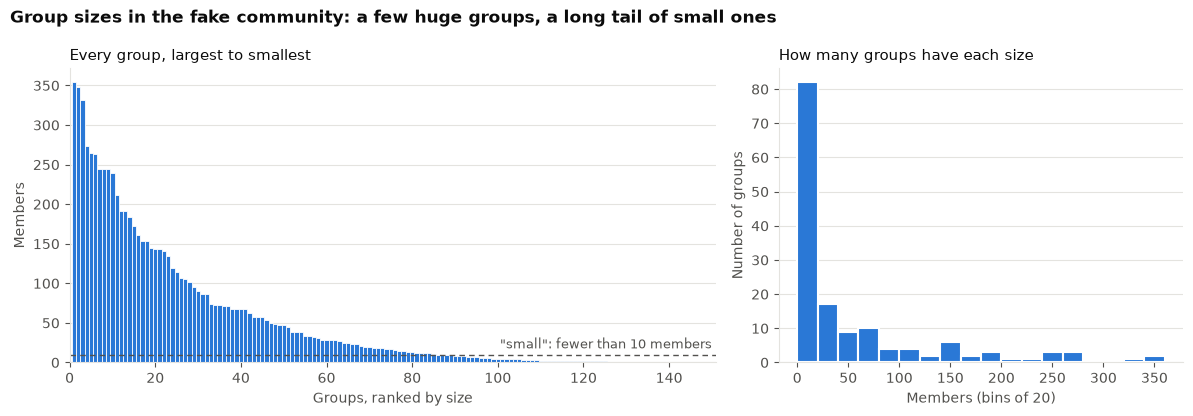

In [10]:
INK, MUTED, GRID, BLUE = '#0b0b0b', '#52514e', '#e4e3df', '#2a78d6'
plt.rcParams.update({'font.size': 10, 'axes.edgecolor': GRID, 'axes.labelcolor': MUTED, 'xtick.color': MUTED,
                     'ytick.color': MUTED, 'axes.spines.top': False, 'axes.spines.right': False})
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4.2), gridspec_kw=dict(width_ratios=[1.6, 1]))

ranked = np.sort(sizes.to_numpy())[::-1]
a1.bar(np.arange(1, len(ranked) + 1), ranked, width=1.0, color=BLUE, edgecolor='white', linewidth=0.6)
a1.axhline(SMALL, color=MUTED, linewidth=1, linestyle=(0, (4, 3)))
a1.text(len(ranked), SMALL + 4, f'"small": fewer than {SMALL} members', ha='right', va='bottom', color=MUTED, fontsize=9)
a1.set_title('Every group, largest to smallest', loc='left', color=INK, fontsize=11)
a1.set_xlabel('Groups, ranked by size')
a1.set_ylabel('Members')
a1.set_xlim(0, len(ranked) + 1)
a1.grid(axis='y', color=GRID, linewidth=0.8)
a1.set_axisbelow(True)

bins = np.arange(0, ranked.max() + 20, 20)
a2.hist(sizes, bins=bins, color=BLUE, edgecolor='white', linewidth=1.5)
a2.set_title('How many groups have each size', loc='left', color=INK, fontsize=11)
a2.set_xlabel('Members (bins of 20)')
a2.set_ylabel('Number of groups')
a2.grid(axis='y', color=GRID, linewidth=0.8)
a2.set_axisbelow(True)

fig.suptitle('Group sizes in the fake community: a few huge groups, a long tail of small ones',
             x=0.01, ha='left', color=INK, fontsize=12.5, fontweight='bold')
fig.tight_layout()
fig.savefig(FIGS / 'group_sizes.png', dpi=160, bbox_inches='tight')
plt.show()

**Colab only:** this cell packs the files into `sim_v1.zip` and downloads it. Locally it does nothing.

In [11]:
if 'google.colab' in sys.modules:
    from google.colab import files
    with zipfile.ZipFile('sim_v1.zip', 'w') as z:
        for f in COLUMNS:
            z.write(OUT / f, f'sim_v1/{f}')
    files.download('sim_v1.zip')
else:
    print('Running locally: the files are already in data/sim_v1')

Running locally: the files are already in data/sim_v1
